# AP 155 Lab Exercise
---
## Exercise 11: Fourier transform

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Buhangin, Ahrystan Deniz S.
- _Student No._: 2024-07766
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

Unaliased and aliased signals in both time and frequency domain

<img src="Figures/aliasedunaliased.png" alt="Alt text" width=45%>


### Report discussion

#### Problem 1
Changing the frequency of the input square wave shifts the fundamental frequency of its fourier transform exactly to the frequency it is changed into. The succeeding peaks in the fourier domain, on the other hand, compresses the distance at which the succeeding peaks are found.

#### Problem 2
Lowering the number of sample points degrades the spectral separation in the frequency domain, blurring closely spaced frequency components and making noise filtering less effective.
 
#### Problem 3
The figure shows the unalised and aliased signals with a frequency of 18Hz. We can easily observe that in the frequency domain, the aliased signal spikes at around 2Hz while the unaliased signal spikes at the expected 18Hz. The sampling frequency in the aliased case is 20Hz, which means that its Nyquist frequency is 10Hz. We can then note that the signal spikes at exactly the Nyquist frequency minus the overflow frequency.



### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy as sc

### Problem 1: Exploring FT of varying waveforms

Given the waveforms from the pool below, produce a $1\times3$ plot containing the following: 
1) the signal, with its variations, 
2) the magnitude of its Fourier transform, and 
3) the phase information of the transform (up to you if unwrapped or not). 
    
Discussion: 2-3 sentences explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?

Waveforms you can try (prefarably non-sinusoidal):
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function (vary sigma)
- Finite-time sinusoid
- Gaussian wave packet
- Dirac-delta 

(-50.0, 50.0)

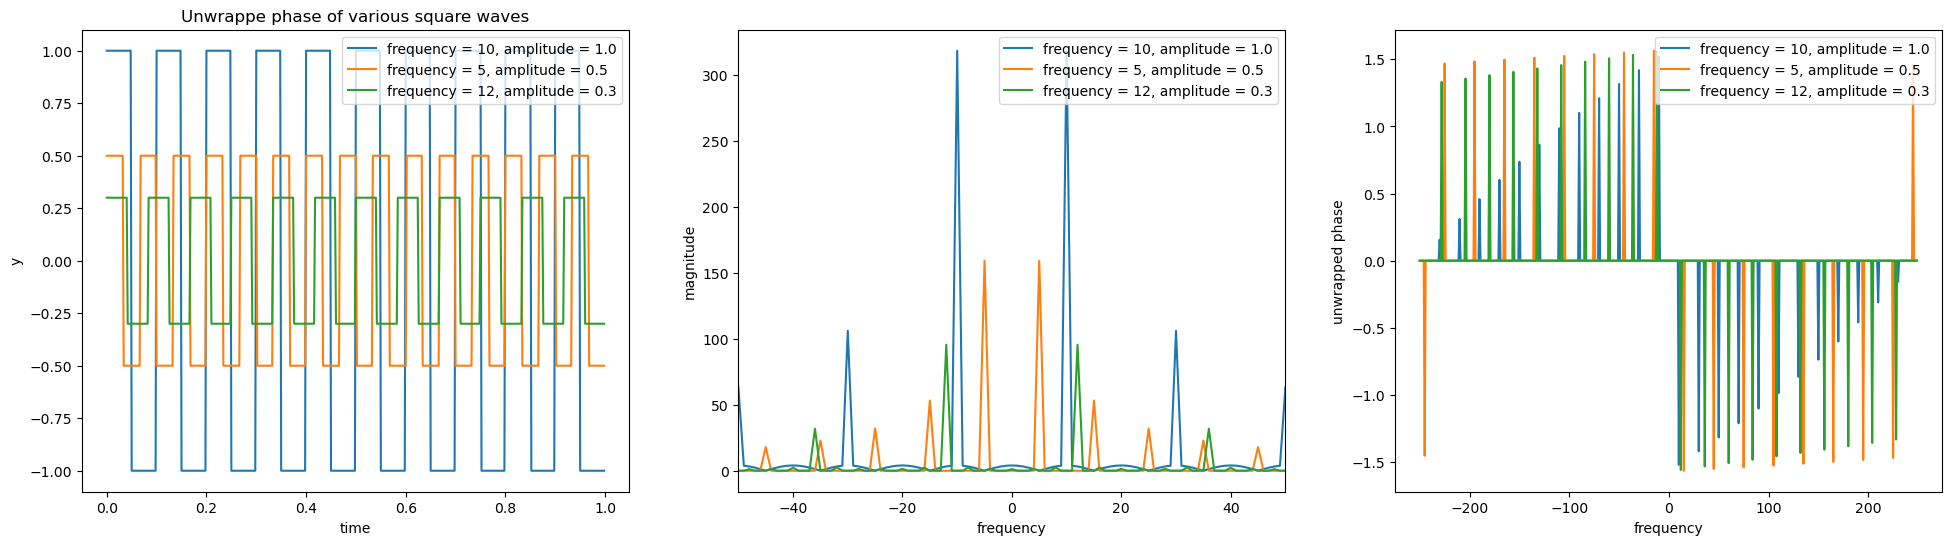

In [2]:
N = 500
t = np.linspace(0, 1, N, endpoint=False)
signal_freq = 10
dt = t[1] - t[0]
def square(t, freq, multiplier=1, offset=0):
    return offset+sc.signal.square(2*np.pi*freq*t)*multiplier
def fft_magn(f, t, freq, multiplier=1, offset=0):
    return np.fft.fftshift(np.fft.fft(f(t, freq, multiplier, offset)))
def fft_ph(wave):
    raw_fft = np.fft.fft(wave)
    shifted_fft = np.fft.fftshift(raw_fft)
    magn = np.abs(shifted_fft)
    ph = np.angle(shifted_fft)

    ph[magn < 0.05*np.max(magn)] = 0.0

    return np.unwrap(ph)

square_1 = square(t, signal_freq)
square_2 = square(t, signal_freq+5, 0.5)
square_3 = square(t, signal_freq+2, 0.3)

fft_magn_sq = np.fft.fftshift(np.fft.fft(square(t, signal_freq)))
fft_freq_sq = np.fft.fftshift(np.fft.fftfreq(N, dt))
fft_ph_sq = np.angle(fft_magn_sq)

fig, axs = plt.subplots(1, 3, figsize=(24,6))
axs[0].plot(t, square_1, label='frequency = 10, amplitude = 1.0')
axs[0].plot(t, square_2, label='frequency = 5, amplitude = 0.5')
axs[0].plot(t, square_3, label='frequency = 12, amplitude = 0.3')
axs[0].set_title('Various square waves in time domain')
axs[0].set_xlabel('time')
axs[0].set_ylabel('y')
axs[0].legend(loc='upper right')
axs[1].plot(fft_freq_sq, abs(fft_magn(square, t, signal_freq)), label='frequency = 10, amplitude = 1.0')
axs[1].plot(fft_freq_sq, abs(fft_magn(square, t, signal_freq-5, 0.5)), label='frequency = 5, amplitude = 0.5')
axs[1].plot(fft_freq_sq, abs(fft_magn(square, t, signal_freq+2, 0.3)), label='frequency = 12, amplitude = 0.3')
axs[0].set_title('Various square waves in the frequency domain')
axs[1].set_xlabel('frequency')
axs[1].set_ylabel('magnitude')
axs[1].legend()
axs[2].plot(fft_freq_sq, fft_ph(square_1), label='frequency = 10, amplitude = 1.0')
axs[2].plot(fft_freq_sq, fft_ph(square_2), label='frequency = 5, amplitude = 0.5')
axs[2].plot(fft_freq_sq, fft_ph(square_3), label='frequency = 12, amplitude = 0.3')
axs[0].set_title('Unwrappe phase of various square waves')
axs[2].set_xlabel('frequency')
axs[2].set_ylabel('unwrapped phase')
axs[2].legend(loc='upper right')
axs[1].set_xlim((-50, 50))

#### Problem 1 code summary

The above code implements three square waves with varying frequency and amplitude. The fourier transforms of these waves are then plotted and analysed along with their unwrapped phases.

### Problem 2: Signal Processing in 1D (Fill in the blanks/Code to get to the desired result)

Steps performed: 

1) Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal
2) Add noise (gaussian noise)
3) Add a window (Hann)
4) Get fft of the noisy signal
5) filter frequencies below a threshold
6) get the inverse fft
7) compare the result

Discussion: Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why? (Answer in ~3 sentences)


In [3]:
#Make a wave (cosine or sine) - you can do combo of waves
N = 25000
N_2 = 1000
dt = 0.0002 #if spacing is 0.0002, then frequency is 5000 Hz 
t_ = np.arange(N)*dt
t2_ = np.arange(N_2)*dt
freqs = [130, 230, 180]
phase = [np.pi/3, np.pi/4, np.pi/6]

cont_signal = lambda t, freq: np.cos(2*np.pi*freq*t)

signal_original = np.sum([np.cos(2*np.pi*f*t_ + p) for f, p in zip(freqs, phase)], axis=0)
signal_original2 = np.sum([np.cos(2*np.pi*f*t2_ + p) for f, p in zip(freqs, phase)], axis=0)

(0.0, 0.3)

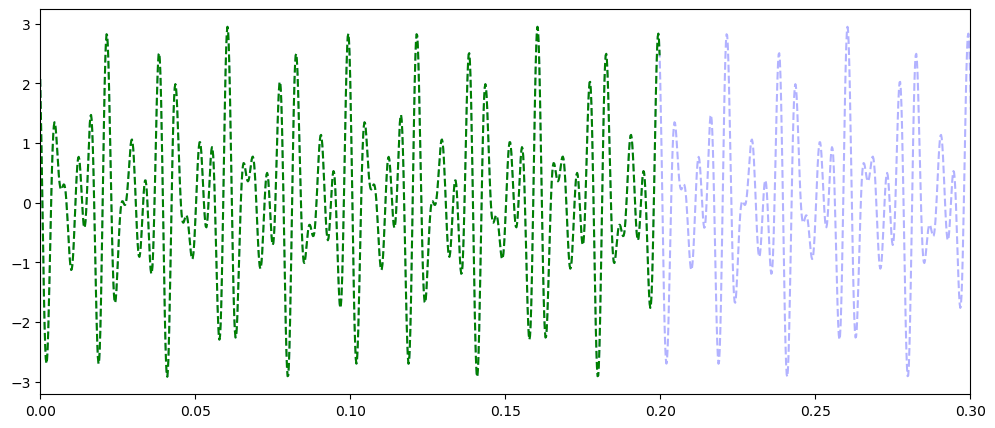

In [4]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, signal_original, 'b--', alpha=0.3)
ax.plot(t2_, signal_original2, 'g--')
ax.set_xlim(0,0.3)

In [5]:
#FILL: Plot the fourier transform of the clean, original signal

Text(0, 0.5, 'amplitude')

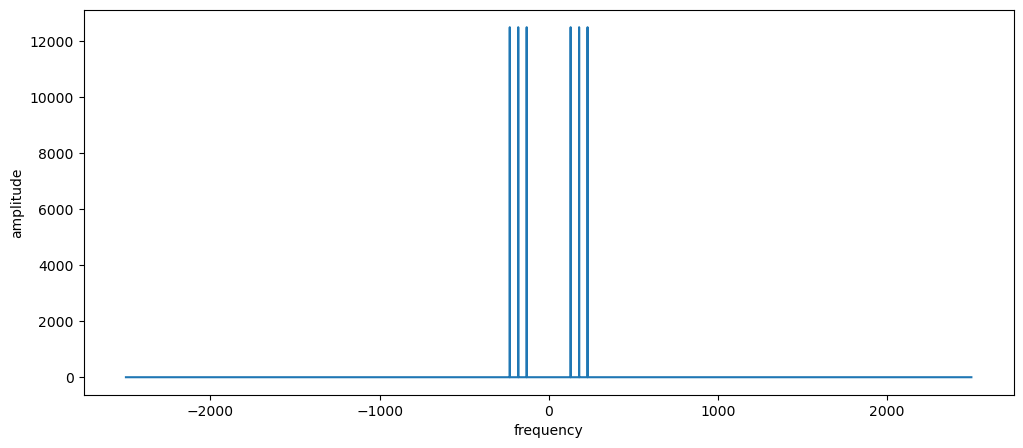

In [6]:
fft = np.fft.fftshift(np.fft.fft(signal_original))

plt.figure(figsize=(12,5))
plt.plot(np.fft.fftshift(np.fft.fftfreq(N, dt)), abs(fft))
plt.xlabel('frequency')
plt.ylabel('amplitude')

In [7]:
rng = np.random.default_rng()

#Define parameters of Gaussian noise)
mean = 0
std = 2

noise = rng.normal(loc = mean, scale = std, size = len(t_)) #Add noise to every data point
#Noisy data here
noisy_data = signal_original + noise*5

(0.0, 0.3)

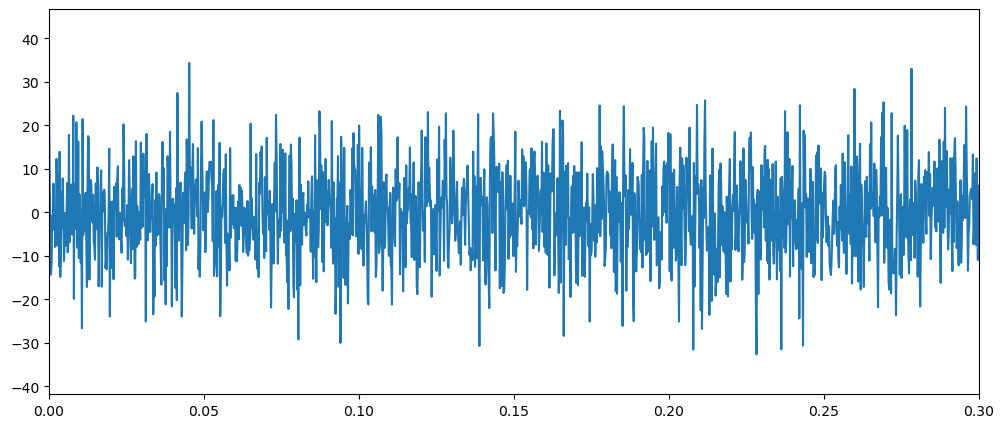

In [8]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, noisy_data)
ax.set_xlim(0,0.3)

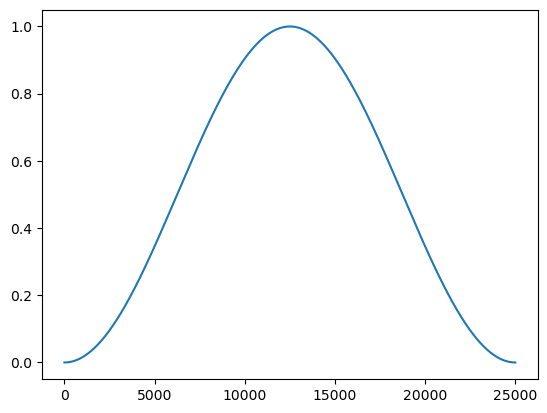

In [9]:
#Create a window the size of the data length
window = np.hanning(len(noisy_data)) 
plt.plot(window)

In [10]:
#fourier of hanning window
windowSigPeaks = np.abs(np.fft.fftshift(np.fft.fft(window)))
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))


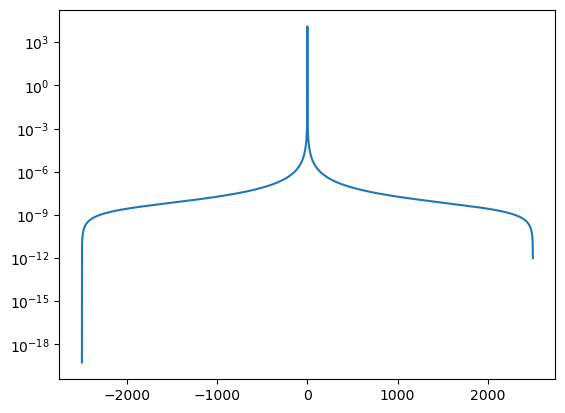

In [11]:
plt.plot(windowSigFreqs, windowSigPeaks)
plt.yscale('log')

In [12]:
noisyFourier = np.fft.fft(noisy_data*window)
noisySigPeaks = np.abs(np.fft.fftshift(noisyFourier))


Text(0.5, 1.0, 'Fourier transform of noisy data')

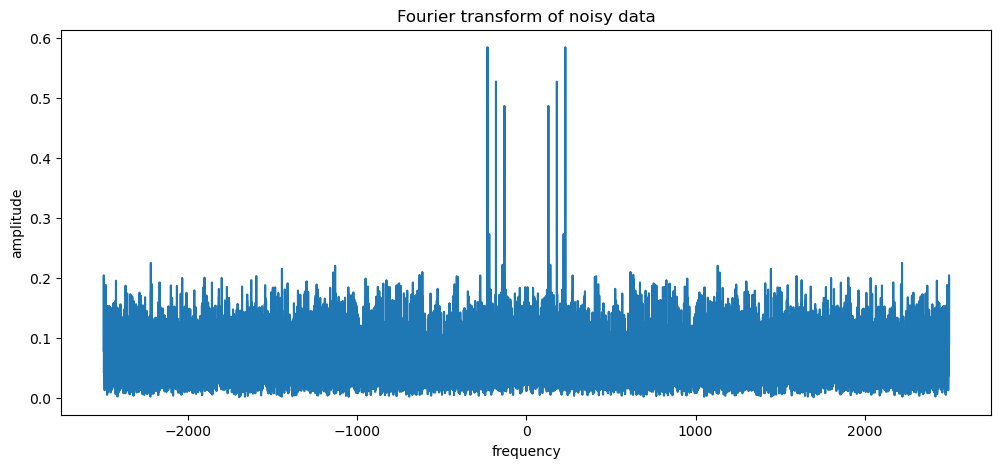

In [13]:
# Fill: Plot the magnitude of fourier transform of the noisy data multiplied by the hanning window

plt.figure(figsize=(12,5))
plt.plot(np.fft.fftshift(np.fft.fftfreq(N, dt)), noisySigPeaks / (N/2))
plt.xlabel('frequency')
plt.ylabel('amplitude')
plt.title('Fourier transform of noisy data')

(array([1.0928e+04, 1.1511e+04, 2.3790e+03, 1.6800e+02, 6.0000e+00,
        2.0000e+00, 0.0000e+00, 0.0000e+00, 2.0000e+00, 4.0000e+00]),
 array([   7.50053444,  738.1453315 , 1468.79012856, 2199.43492562,
        2930.07972269, 3660.72451975, 4391.36931681, 5122.01411388,
        5852.65891094, 6583.303708  , 7313.94850507]),
 <BarContainer object of 10 artists>)

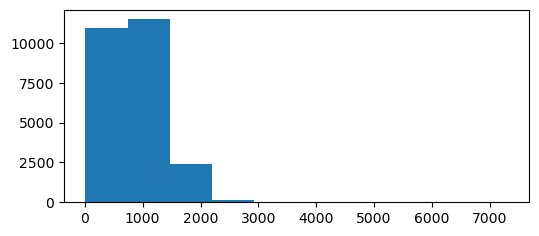

In [14]:
# Fill: Find a suitable threshold value to filter the noise in fourier space

plt.figure(figsize=(6, 2.5))
plt.hist(noisySigPeaks)

Text(0.5, 1.0, 'Filtered signal in frequency domain')

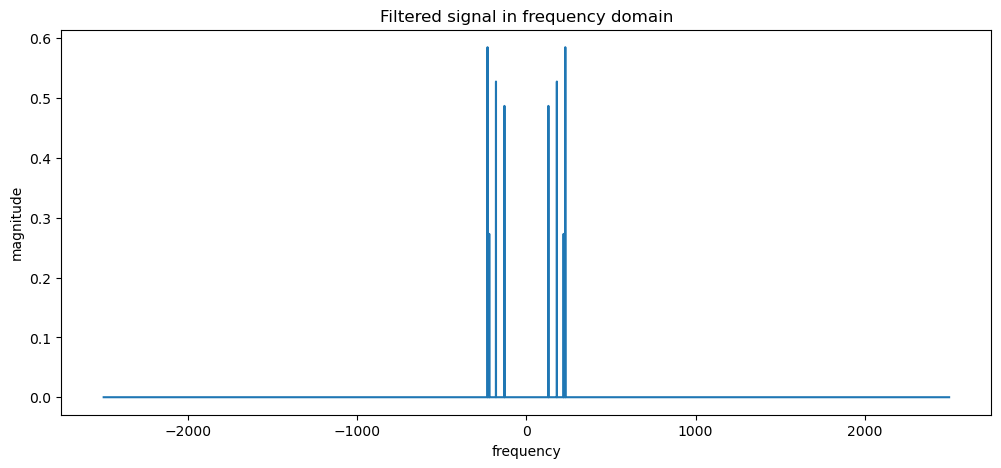

In [15]:
# Fill: with the cleaned signal in fourier space, convert it back to the time domain
fft_noisy_raw = np.fft.fft(noisy_data*window)

threshold = 3200
fft_filtered = noisyFourier.copy()
fft_filtered[np.abs(noisyFourier) < threshold] = 0
fft_filtered_shifted = np.fft.fftshift(fft_filtered)

plt.figure(figsize=(12,5))
plt.plot(np.fft.fftshift(np.fft.fftfreq(N, dt)), np.abs(fft_filtered_shifted / (N/2)))
plt.xlabel('frequency')
plt.ylabel('magnitude')
plt.title('Filtered signal in frequency domain')

#### Problem 2 code summary

The above code implements a sinusioidal wave with 3 different frequencies. A Gaussian noise and a Hanning window are then applied. The resulting signal is then taken to the frequency domain, cleaned using a an amplitude mask, and is plotted to be compared with the original signal.

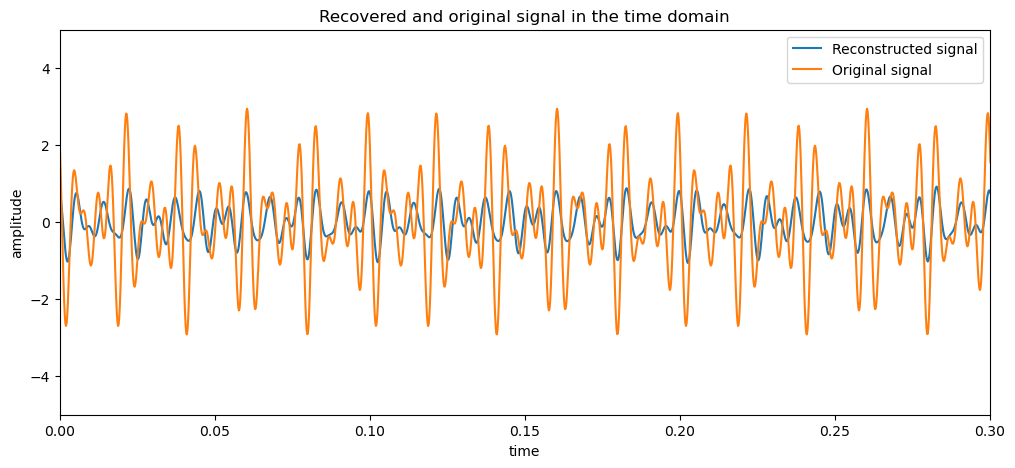

In [16]:
# Plot the recovered signal
recoveredSignal = np.fft.ifft(np.fft.ifftshift(fft_filtered_shifted)).real

fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, recoveredSignal, label='Reconstructed signal')
ax.plot(t_, signal_original, label='Original signal')
ax.set_title('Recovered and original signal in the time domain')
ax.set_ylabel('amplitude')
ax.set_xlabel('time')
ax.set_xlim(0,0.3)
ax.set_ylim(-5, 5)
ax.legend(loc='upper right')

### Problem 3: Aliasing
1) Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.
3) Get their fourier transforms. Are they the same?
4) Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.
   
Discussion: Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave

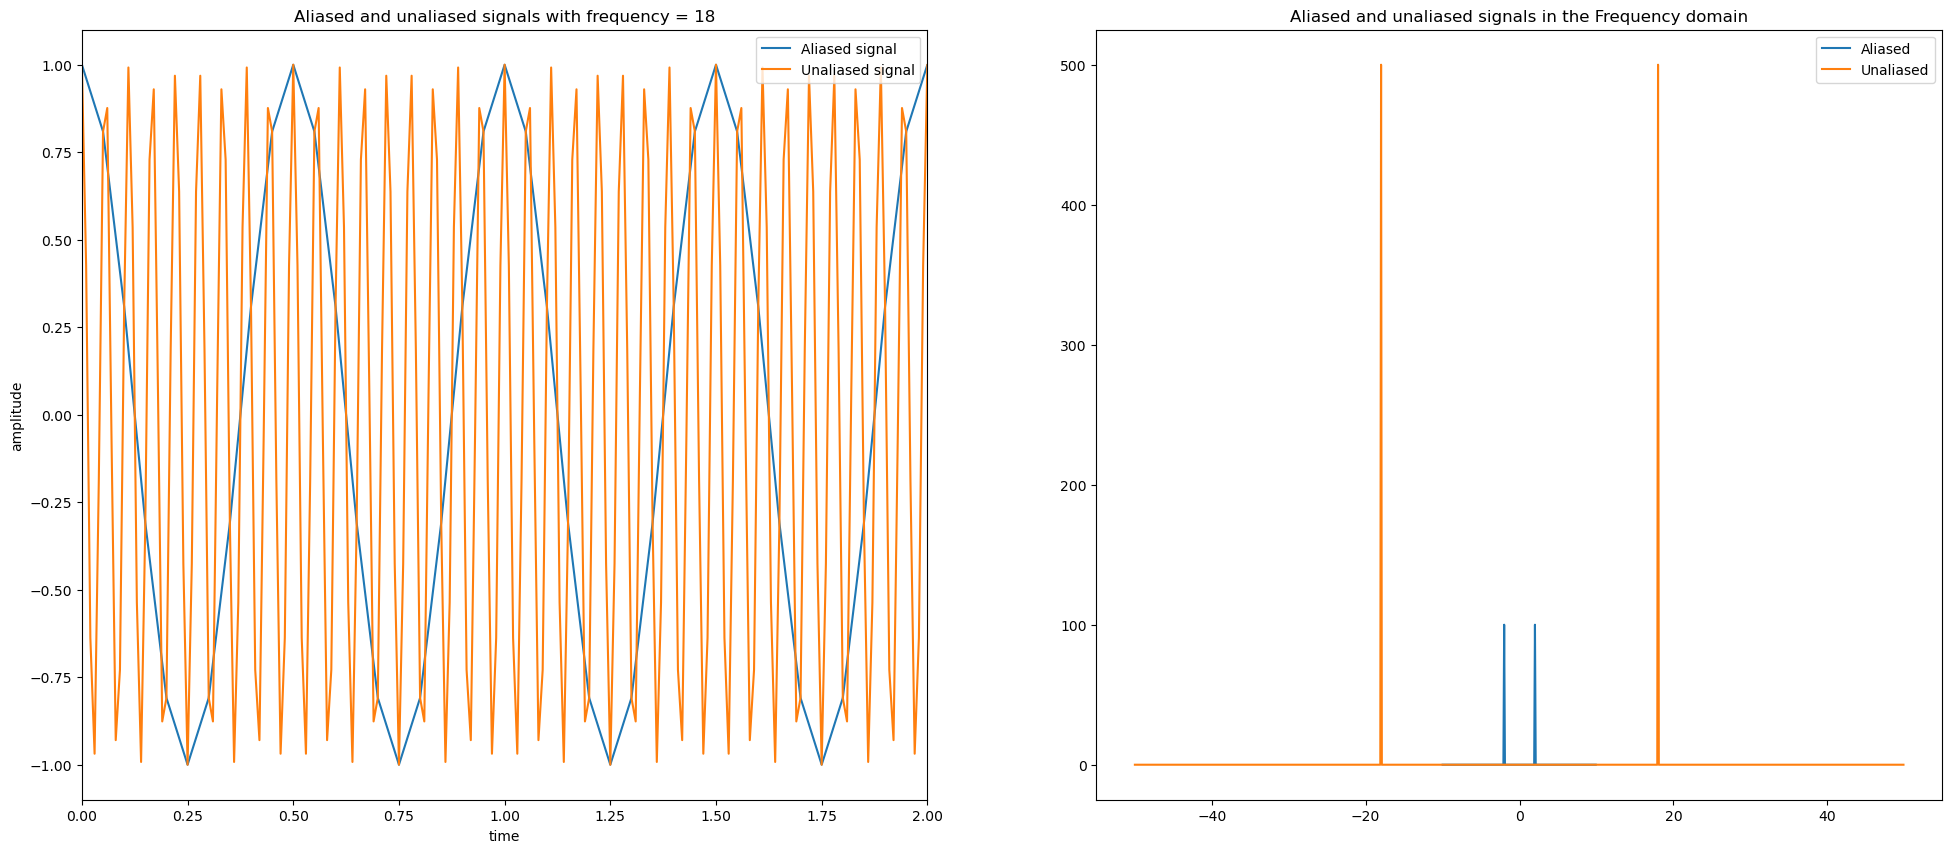

In [17]:
N_sample = 200
N_unaliased = 1000
t = 10
dt = t/N_sample
dt_un = t/N_unaliased
t_sample = np.arange(N_sample)*dt
t_unalised = np.arange(N_unaliased)*dt_un

cont_signal = lambda t, freq: np.cos(2*np.pi*freq*t)

freq = 18
discrete_signal = cont_signal(t_sample, freq)
dis_unaliased = cont_signal(t_unalised, 18)

fft = np.fft.fftshift(np.fft.fft(discrete_signal))
fft_un = np.fft.fftshift(np.fft.fft(dis_unaliased))

fig, ax = plt.subplots(1, 2, figsize=(24,10))
ax[0].plot(t_sample, discrete_signal, label='Aliased signal')
ax[0].plot(t_unalised, dis_unaliased, label='Unaliased signal')
ax[0].set_title('Aliased and unaliased signals with frequency = 18')
ax[0].set_xlim(0, 2)
ax[0].set_xlabel('time')
ax[0].set_ylabel('amplitude')
ax[0].legend(loc='upper right')
ax[1].plot(np.fft.fftshift(np.fft.fftfreq(N_sample, dt)), abs(fft), label='Aliased')
ax[1].plot(np.fft.fftshift(np.fft.fftfreq(N_unaliased, dt_un)), abs(fft_un), label='Unaliased')
ax[1].set_title('Aliased and unaliased signals in the Frequency domain')
ax[1].legend()
plt.savefig('/home/jovyan/Buhangin_AP155/AP155_TX1_1sAY2627/ahrystanB/Figures/aliasedunaliased.png')
fig.show()

#### Problem 3 code summary

The above code implements the Fourier transforms of a signal whose sampling frequency is above the Nyquist frequency, and a signal which has a Nyquist frequency larger than the same sampling frequency.

---
## Section 3: Notes

In [18]:
import numpy as np
import matplotlib.pyplot as plt

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way? 

It cleanly splits the real and imaginary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

(0.0, 4.0)

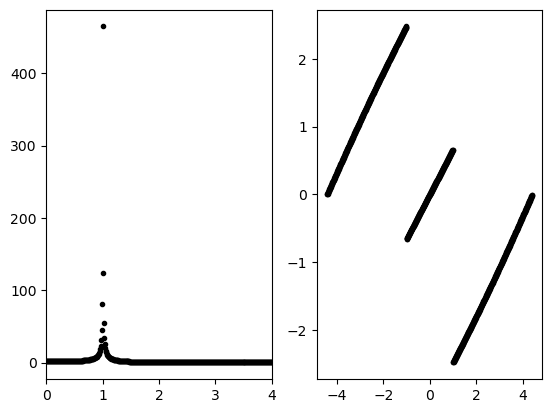

In [19]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

freqs = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(freqs, Yk_mag, "k.")
ax[1].plot(freqs, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

### Waveforms of interest
- Sinusoid (single frequency, varying phase shift)
- Sum of sinusoids with different frequencies and phases
- Product of sinusoids with different frequencies and phases
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function
- Finite-time sinusoid
- Gaussian wave packet

In [20]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)

Text(0, 0.5, 'x')

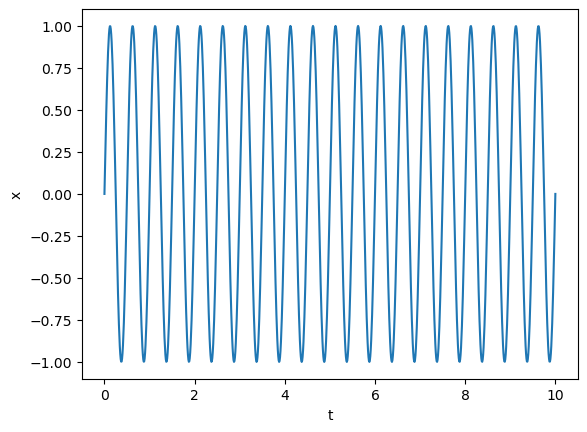

In [21]:
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [22]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

Signature: np.fft.fftfreq(n, d=1.0)
Docstring:
Return the Discrete Fourier Transform sample frequencies.

The returned float array `f` contains the frequency bin centers in cycles
per unit of the sample spacing (with zero at the start).  For instance, if
the sample spacing is in seconds, then the frequency unit is cycles/second.

Given a window length `n` and a sample spacing `d`::

  f = [0, 1, ...,   n/2-1,     -n/2, ..., -1] / (d*n)   if n is even
  f = [0, 1, ..., (n-1)/2, -(n-1)/2, ..., -1] / (d*n)   if n is odd

Parameters
----------
n : int
    Window length.
d : scalar, optional
    Sample spacing (inverse of the sampling rate). Defaults to 1.

Returns
-------
f : ndarray
    Array of length `n` containing the sample frequencies.

Examples
--------
>>> signal = np.array([-2, 8, 6, 4, 1, 0, 3, 5], dtype=float)
>>> fourier = np.fft.fft(signal)
>>> n = signal.size
>>> timestep = 0.1
>>> freq = np.fft.fftfreq(n, d=timestep)
>>> freq
array([ 0.  ,  1.25,  2.5 , ..., -3.75, -2.5 , -1

### Plotting

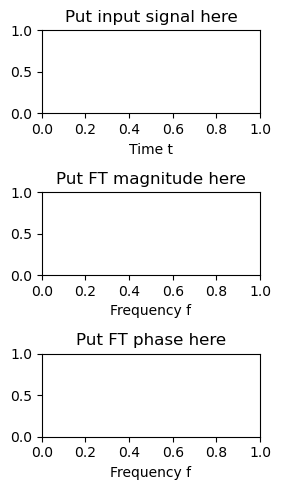

In [23]:
fig, ax = plt.subplots(3, 1, figsize=(3, 5))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

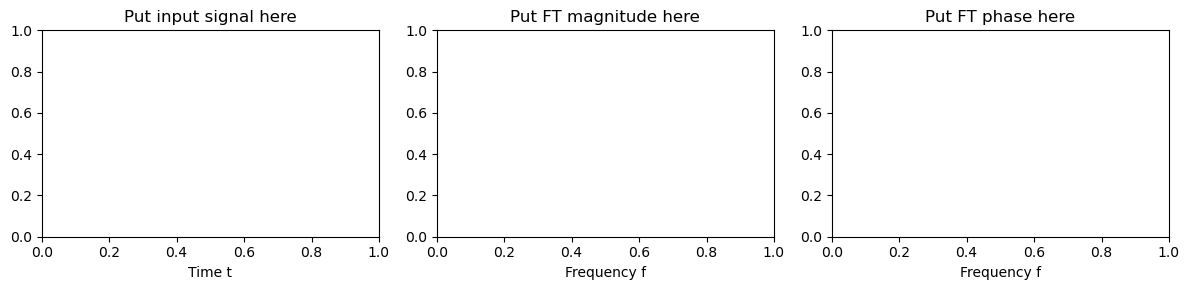

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

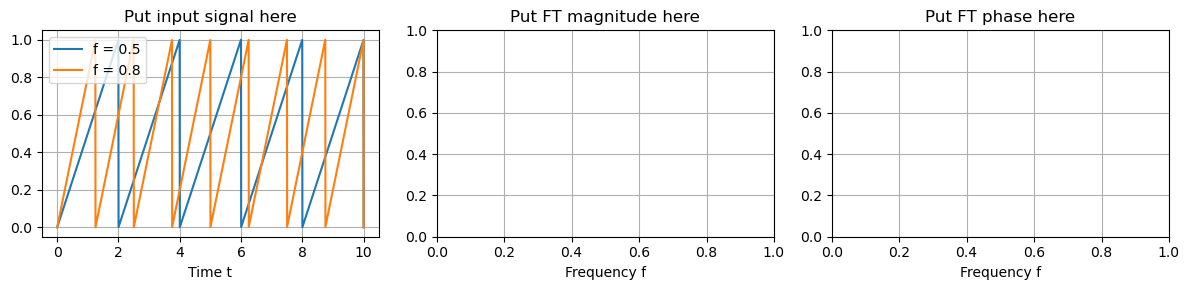

In [25]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

## 1-D convolution

In [26]:
a = [1,1,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,1,0,1,1,0,0,0,0]
v = [1,1,1]



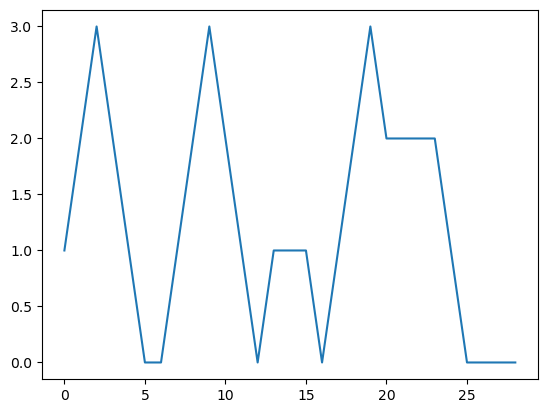

In [27]:
plt.plot(np.arange(len(np.convolve(a,v, mode='full'))), np.convolve(a,v, mode='full'))

### Convolution attempt (bringing circuits analogy) 

In [28]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
N = 500
t = np.linspace(0, 1, N, endpoint=False)
t_input = np.linspace(0, 5, N*5, endpoint=False)
signal_freq = 5
# dt = t[1] - t[0]
# nonsinu_signal = signal.square(2 * np.pi * signal_freq * t)

In [29]:
tau = 0.1
h_t = np.exp(-t/tau)
input_signal = signal.square(2 * np.pi * signal_freq * t_input) #cont_signal(t, freq)

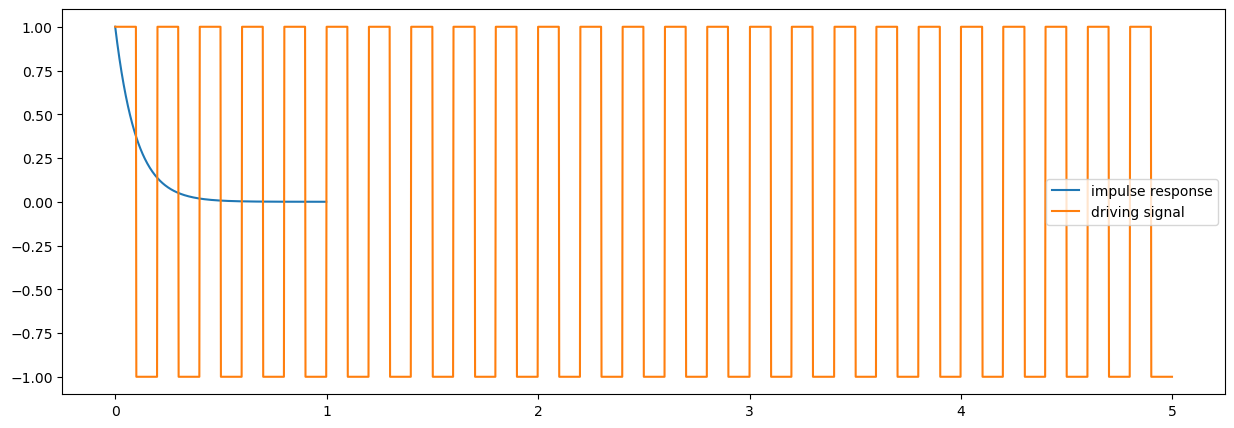

In [30]:
fig, ax = plt.subplots(figsize = (15,5))
ax.plot(t, h_t, label = "impulse response")
ax.plot(t_input, input_signal, label= "driving signal")
ax.legend()

In [31]:
response = np.convolve(input_signal, h_t, mode = "same")

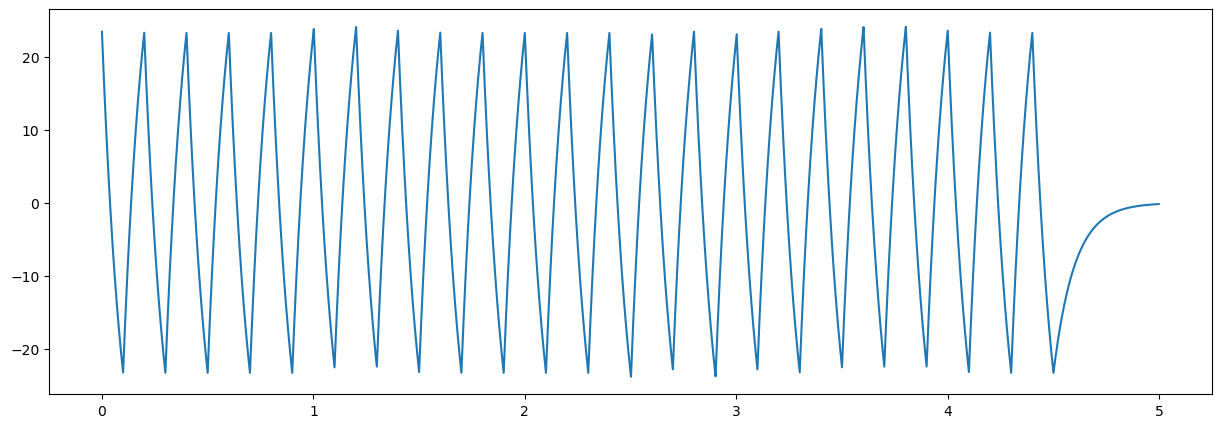

In [32]:
fig, ax = plt.subplots(figsize = (15,5))
#ax.plot(t, input_signal)
ax.plot(t_input, response)

In [33]:
fourier_length = len(h_t) + len(input_signal) - 1

In [34]:
fourier_input = np.fft.fft(input_signal, n = fourier_length)
fourier_h = np.fft.fft(h_t, n = fourier_length)

In [35]:
fourier_response = fourier_h*fourier_input 

In [36]:
response = np.real(np.fft.ifft(fourier_response))

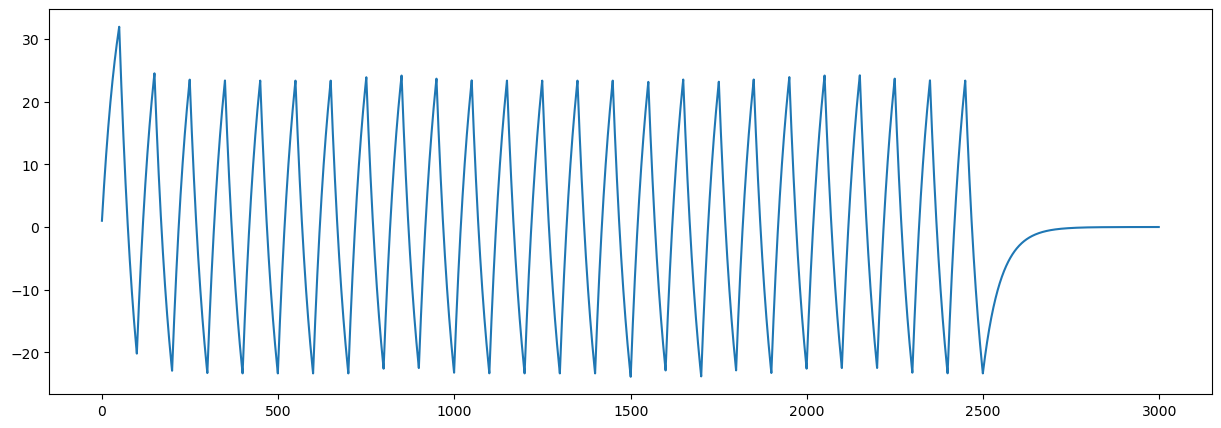

In [37]:
fig, ax = plt.subplots(figsize = (15,5))

ax.plot(response)